<a href="https://colab.research.google.com/github/gachet/ad-1-26/blob/main/algo/Actividad_3_11_2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

In [2]:
#Carga de datos
URL = "https://drive.google.com/uc?id=1VNg7M4u4wluLLqEeSgU3EEduFd6Q84NZ"
df = pd.read_csv(URL)

# Vista rápida
display(df.head())

,Size,Bedrooms,Price
0,2104,3,399900
1,1600,3,329900
2,2400,3,369000
3,1416,2,232000
4,3000,4,539900


In [3]:
# Selección de columnas (igual lógica, distintos nombres)
features = df[['Size', 'Bedrooms']]
target = df['Price']

In [4]:
# Normalización "a mano" como en el original (media y desviación estándar)
Xnorm = (features - features.mean()) / features.std()

# Agregamos columna de 1s para el término independiente (bias)
Xnorm = np.c_[np.ones(Xnorm.shape[0]), Xnorm]

# Inicialización de parámetros y configuración del descenso de gradiente
params = np.zeros(Xnorm.shape[1])
eta = 0.01          # tasa de aprendizaje
tol = 1e-5          # umbral de parada por cambio mínimo en la pérdida

loss_trace = []
prev_loss = float('inf')
iter_idx = 0

# Bucle principal de optimización (misma mecánica)
while True:
    y_pred = Xnorm.dot(params)                 # predicciones
    resid = y_pred - df['Price']               # errores
    grad = Xnorm.T.dot(resid) / len(df)        # gradiente promedio
    params = params - eta * grad               # actualización de parámetros

    loss = np.mean(resid**2) / 2               # función de pérdida (MSE/2)
    loss_trace.append(loss)

    # Criterio de parada: cambio pequeño en la pérdida
    if abs(prev_loss - loss) < tol:
        print(f"Convergió en la iteración {iter_idx}")
        break

    prev_loss = loss
    iter_idx += 1

print("Parámetros (theta):", params)


Convergió en la iteración 3223
Parámetros (theta): [340412.65957447 110630.99718115  -6649.42117312]


In [5]:
# Solución cerrada por ecuación normal (misma idea, distinto nombre de variable)
beta_cerrada = np.linalg.inv(Xnorm.T.dot(Xnorm)).dot(Xnorm.T).dot(target)
print("Coeficientes (ecuación normal):")
print(beta_cerrada)

Coeficientes (ecuación normal):
[340412.65957447 110631.05027885  -6649.47427082]


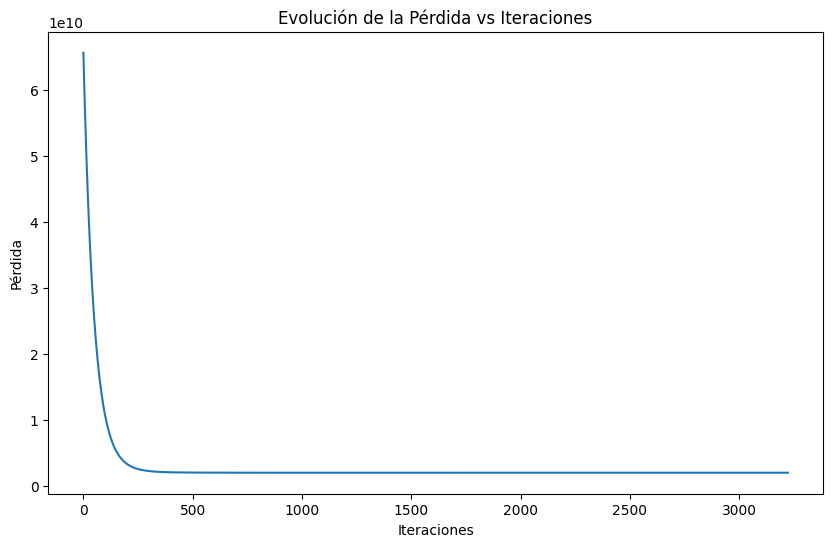

In [6]:
# Curva de entrenamiento de la pérdida
plt.figure(figsize=(10, 6))
plt.plot(range(len(loss_trace)), loss_trace)
plt.xlabel("Iteraciones")
plt.ylabel("Pérdida")
plt.title("Evolución de la Pérdida vs Iteraciones")
plt.show()